# Is the adversary's extra damage in the original subcomponents? (E20)

*2026-10-21. Record and full tables: `reports/analyses/2026-10-21_analysis_cancellation-complement.md`. Plan:
`reports/plans/2026-10-21_plan_cancellation-complement.md`. Follows E17, `notebooks/E17_cancellation.ipynb`. Words as in
`GOALS.md` → Terms.*

## The answer

No. The previous experiment inferred that the adversary's extra damage on updated models came from its mask on the
original subcomponents. We measured that directly. On three of the four failing models, removing the adversary's share
of the original subcomponents costs no more than at the original model. On the fourth it carries a fifth of the excess.
Most of the excess sits in the adversary's mask on the dead subcomponents and on Δ, the weights outside them. Part
may come from how that mask combines with the rest. Which of those it is has not been measured.

## What we were trying to test

VPD writes each weight matrix as a sum of rank-one subcomponents $u_c v_c^\top$ plus Δ, the part they leave over. About
9,900 subcomponents are alive: Γ, the importance network, rates them important somewhere on the original model's text.
The rest are dead. VPD's adversarial check keeps at least the importance $g_c(x)$ of each subcomponent. Above that floor
it picks a level $a_c$ that hurts the output most, keeping $g_c + (1-g_c)\,a_c$ of subcomponent $c$. It keeps a level
$a_\Delta$ of Δ, with no floor. Every map we have tried that carries a fine-tune into the subcomponents makes this
check worse on some tasks. The rise over the original model is the adversary's excess.

The previous experiment, E17, removed the adversary's fraction of each subcomponent's change
$d_c = u'_c v'^\top_c - u_c v_c^\top$ and found it explains under a tenth of the excess. It inferred that the rest came
from the adversary's fraction of the original subcomponents, which the updated model would lean on more. This run
measures that. Forward hooks on each decomposed matrix subtract chosen fractions of four blocks of its output. The
blocks are the alive original subcomponents, their changes, the dead subcomponents, and Δ.

The symbols, each a KL divergence in nats from the model to a copy with something removed, on 128 rows of Pile text:

- $F$: the adversary's full mask.
- $F_o$: only the adversary's fraction $(1-g_c)(1-a_c)$ of each alive original subcomponent removed, the changes kept.
- $F_d$: the same fraction of each change removed, the originals kept; this is E17's measurement.
- $F_b$: the same fraction of both, that is of each alive updated subcomponent.

The excess $X = F(\text{state}) - F(W_0)$ then splits exactly into four parts. $O = F_o(\text{state}) - F_o(W_0)$ is
the originals' part. $F_d$ is the changes' part. $I = F_b - F_o - F_d$ is how the two combine. The rest,
$R = [F - F_b](\text{state}) - [F - F_o](W_0)$, is what the mask on the dead subcomponents and on Δ adds. It includes
how they combine with the alive removal. $R$ is a remainder of measured quantities, not a revert of its own.

We read eight updated models, called states, rebuilt from earlier runs' saved files, each under its own adversary.
Component training ran for ten steps on six tasks: three that pass the adversarial check and three that fail it. The
emoticon fine-tune was split two ways: the least-squares split, which fails, and the scaled adjoint split, which
passes. The original model, $W_0$, is read the same way and is the reference for every part.

Two further readings ask which originals matter. In the first, the adversary's levels $a_c$ are shuffled among the alive
subcomponents of each matrix, three times. It asks whether the pattern matters, or any removal of that size would do.
In the second, only one bin of originals is removed: a quarter of the alive subcomponents by mean importance at $W_0$,
or one layer.

A gate ran first on every model: the hooks, with every block at the adversary's fractions, reproduce its own masked
model. They did so to within a billionth of a nat. A control followed: on component training's emoticon state, the
changes' revert and the adversary's KL reproduced E17's values exactly.

## What we expected, and why

- **The originals carry at least half of the excess** on each failing state, with moderate confidence. E17 left them
  as the only large candidate. The risk we named was the rest: the dead subcomponents and Δ.
- **The adversary's pattern over the originals matters**: its own levels cost at least twice what shuffled levels
  cost. Turning every maskable subcomponent down together costs a fiftieth of the adversary's mask. So its choice
  of which to turn down should do the damage.
- **The least important originals carry it**, with low confidence. The two lowest importance quarters should hold at
  least half of the per-bin excess, on three of the four failing states. A subcomponent Γ rates near zero can be removed at
  every position.

In [1]:
import json
from pathlib import Path

from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / 'experiments').is_dir() else Path.cwd().parent
EXP = ROOT / 'experiments/cancellation_complement'
out = json.loads((EXP / 'results/complement.json').read_text())
w0, st, dec = out['W0'], out['states'], out['score']['decomposition']
assert all(out['score']['G1_closure'].values()) and out['C0']['verdict'] == 'pass'
NAMES = {'adjoint emoticon': 'adjoint split, emoticon', 'ct emoticon': 'component training, emoticon',
         'ct r1_t588_v452': 'component training, r1 t588', 'ct r2_t359_v816': 'component training, r2 t359',
         'ct r0_t352_v310': 'component training, r0 t352', 'ct r1_t534_v369': 'component training, r1 t534',
         'ct r2_t275_v2667': 'component training, r2 t275', 'ls emoticon': 'least-squares split, emoticon'}
print(f"original model: adversary {w0['F_all']:.3f} nats, of which the alive originals' revert {w0['F_orig']:.3f}")
print(f"largest gate error {max(abs(r['G1']['kl_closure']) for r in [w0, *st.values()]):.1e} nats")

original model: adversary 0.660 nats, of which the alive originals' revert 0.487
largest gate error 3.7e-09 nats


## 1. Where does the adversary's extra damage come from?

Each bar is one model's adversarial KL, cut into the four parts measured at that model. The original model's bar is at
the top. Its two boundaries are carried down every row as lines: the dotted one at its originals' part, the dashed one
at its total. The excess is whatever extends past the dashed line.

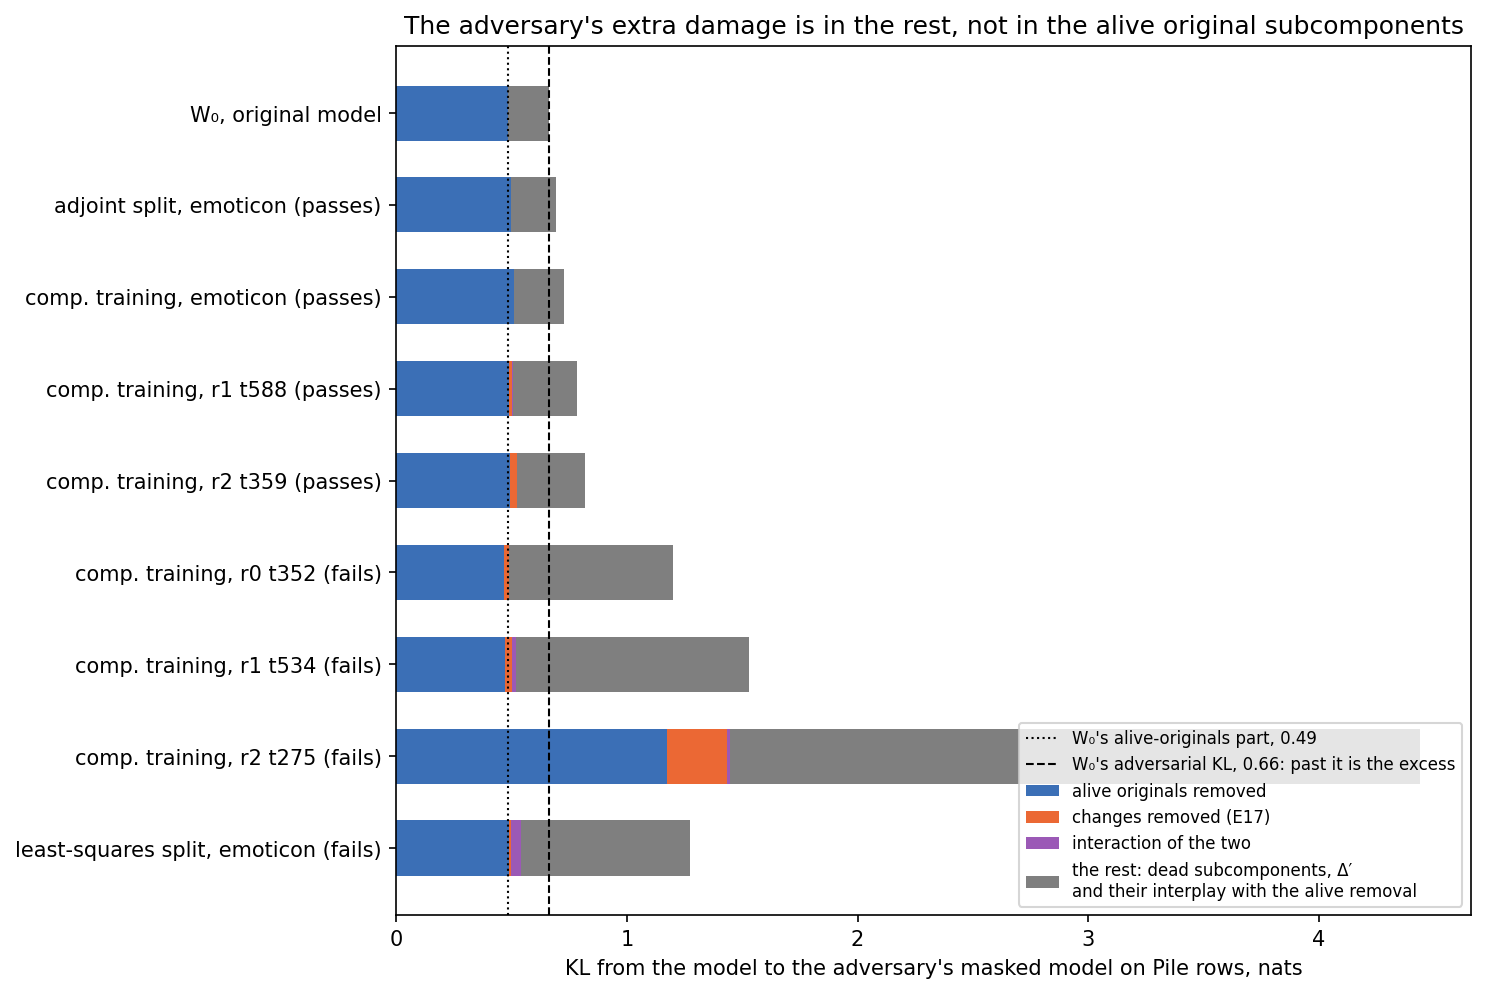

In [2]:
display(Image(EXP / 'figures/decomposition.png'))

**Reading it.** The extra damage is not in the original subcomponents: the grey rest grows and the blue part
does not. On three of the four failing states the blue segment ends on the dotted line. Removing the adversary's share
of the original subcomponents there costs what it costs at the original model. The grey segment holds the dead
subcomponents and Δ, with their interplay with the alive removal. It is 0.17 nats at the original model. On those three
states it is 0.7 to 1.0 nats. Component training on r2 t275, by far the largest update, is the exception. There the
originals' part grows by 0.69 nats, a fifth of the excess. The rest still holds 2.8 nats. The changes and their
interaction with the originals are thin slivers everywhere. The passing states show the same shape at a smaller size.

In [3]:
rows = ['| state | excess, nats | originals | changes and interaction | rest |', '|---|---|---|---|---|']
for k, name in NAMES.items():
    d = dec[k]
    rows.append(f"| {name} | {d['X']:.3f} | {d['O'] / d['X']:.0%} | {(d['F_adv'] + d['I']) / d['X']:.0%} | {d['R'] / d['X']:.0%} |")
display(Markdown('\n'.join(rows)))

| state | excess, nats | originals | changes and interaction | rest |
|---|---|---|---|---|
| adjoint split, emoticon | 0.033 | 33% | -1% | 68% |
| component training, emoticon | 0.068 | 33% | 3% | 64% |
| component training, r1 t588 | 0.122 | 3% | 12% | 86% |
| component training, r2 t359 | 0.157 | 5% | 18% | 77% |
| component training, r0 t352 | 0.541 | -4% | 5% | 99% |
| component training, r1 t534 | 0.868 | -2% | 6% | 96% |
| component training, r2 t275 | 3.777 | 18% | 7% | 75% |
| least-squares split, emoticon | 0.614 | 1% | 8% | 91% |

## 2. Does the adversary's choice over the originals matter more after the update?

The originals' revert under the adversary's own levels, divided by the same revert with the levels shuffled. A ratio of
1 means any removal of that size does the same damage. The dashed line is the original model's own ratio.

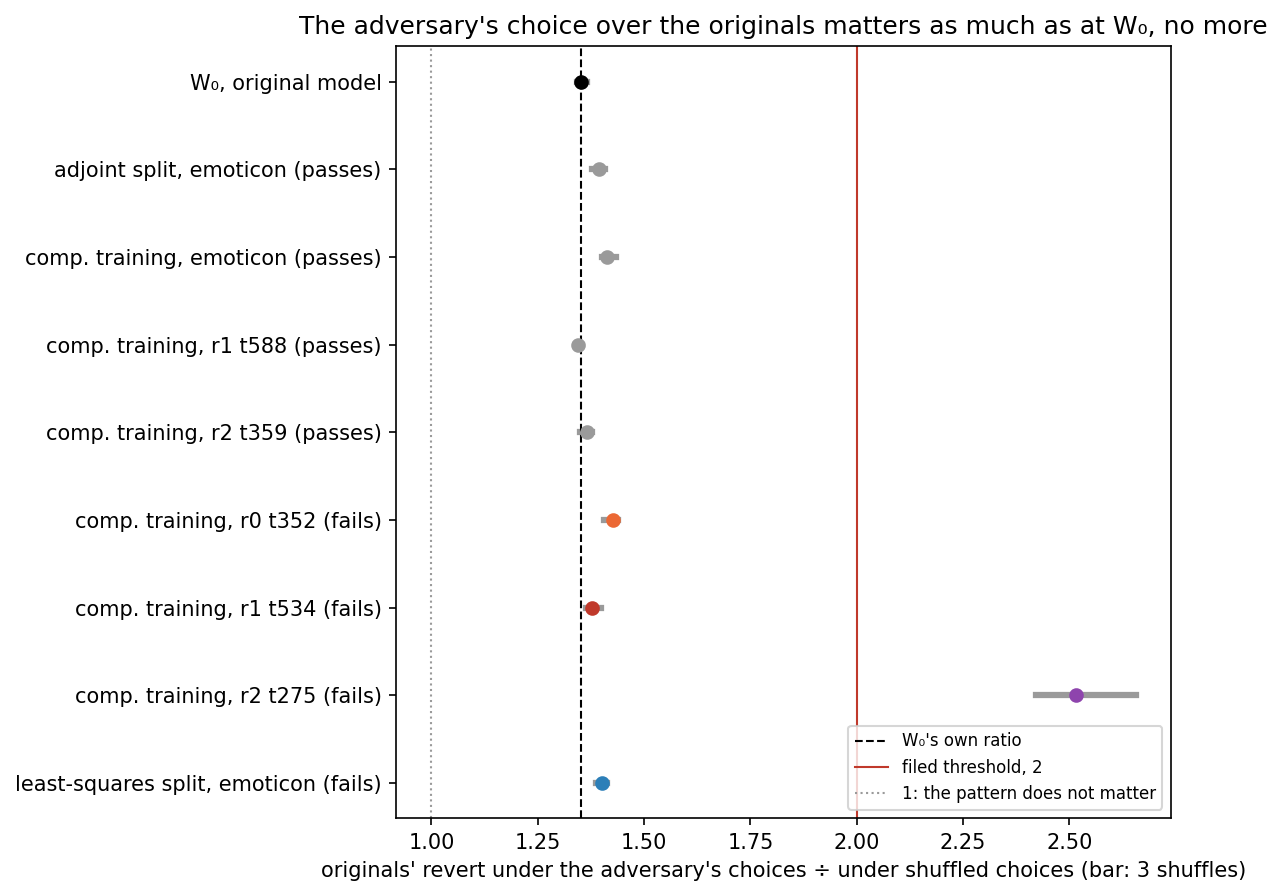

In [4]:
display(Image(EXP / 'figures/pattern.png'))

**Reading it.** The adversary's choice over the originals matters, but no more after the update than before
it. Its levels cost 1.34 to 1.43 times shuffled ones on seven of the eight states, and the original model reads 1.35.
We predicted at least 2, so this prediction failed. A pattern that is ordinary at the original model cannot explain an
excess at the updated one. Component training on r2 t275 again stands apart at 2.5. There, removing the originals
under shuffled levels also costs more than at the original model.

## 3. Which original subcomponents does the updated model lean on?

Each bar removes the adversary's share of one bin of originals only, at the state, minus the same at the original
model. Positive means that bin costs more after the update. The grey band is the plan's noise level of 0.05 nats.

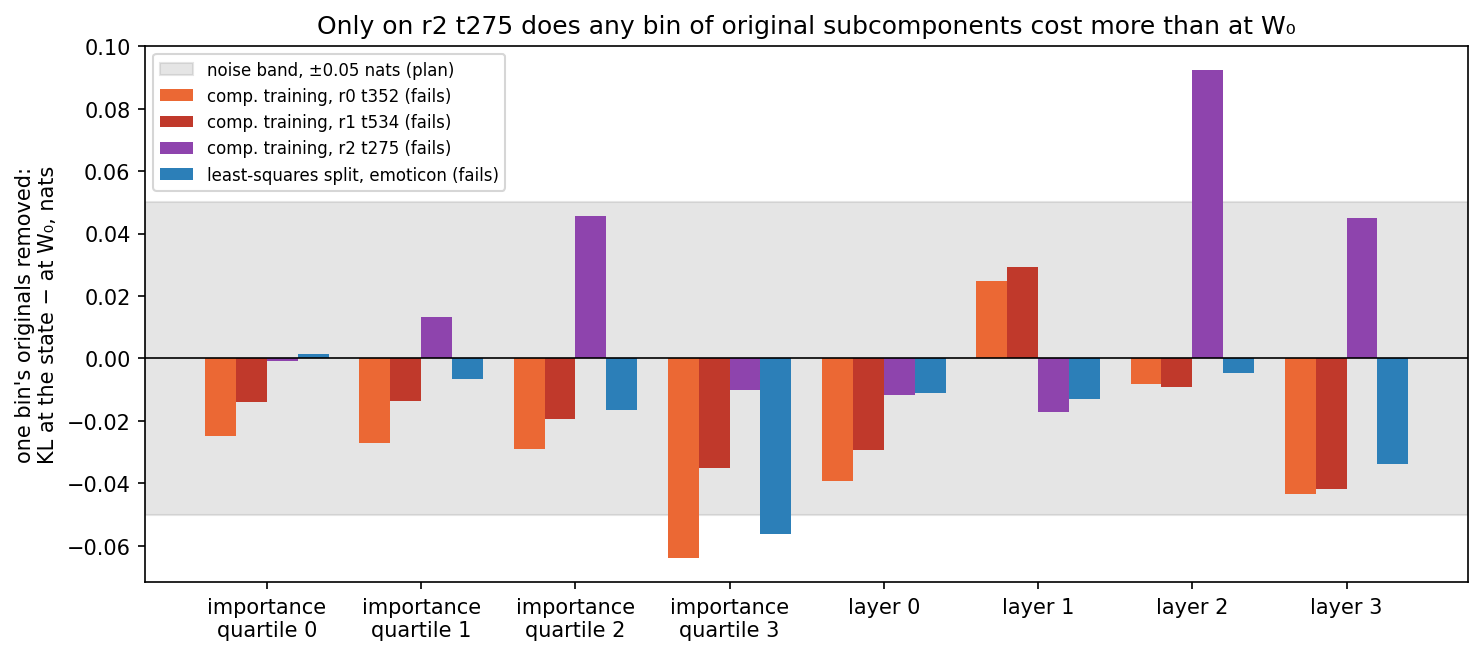

In [5]:
display(Image(EXP / 'figures/bins.png'))

**Reading it.** None, outside r2 t275. Almost every bar sits inside the noise band, and most sit below zero.
The lowest importance quarter, where we expected the excess, reads between −0.025 and 0.001 nats on the four failing
states. On r2 t275 layer 2 reads 0.09, the one bar clearly above the band. With no excess in the originals on three
states, there was nothing for the bins to find there.

## What we learned

The adversary's extra damage on updated models is not in the alive subcomponents. It is not in their changes, nor in
the originals, nor in how the two combine. It sits in the mask on the dead subcomponents and on Δ, or in how that mask
combines with the rest. Component training touches neither: its Δ and its dead subcomponents are exactly the original
model's weights. So the updated model is more sensitive to removing weights the update did not change. E17's reading,
that the updated model leans on originals Γ rates unimportant, is refuted on three of the four failing states. The
brittleness question of `GOALS.md` moves to the part of the model outside the alive subcomponents.

## How compelling is the evidence

The split into four parts is exact. The gate shows the hooks reproduce the adversary's own masked model to a
billionth of a nat on every model. So the rest is a measured total minus measured reverts, not an estimate. The control
reproduced E17 exactly. There is one adversary seed and one update seed per state. Earlier runs put the adversary's
seed spread near 0.05 nats at the original model. The rest grew by 0.5 to 2.8 nats on the failing states.

Blind spots: everything reads Pile text, never the trigger. The rest lumps three things this run cannot separate: the
dead subcomponents, Δ, and their combination with the alive removal. For the least-squares split, Δ also holds the part
of the update the subcomponents cannot express. There the adversary can mask part of the update itself. That route
does not exist for component training.

## Surprises

**Something unexpected happened that I cannot explain yet.** All three filed predictions failed. The excess was
predicted to sit mostly in the original subcomponents. On three of the four failing states their part is zero within
noise, slightly negative. Almost all of it sits instead in the mask on the dead subcomponents and Δ. For component
training those are the same weights as in the original model. This refutes the inference in E17's section 4, and the research
log's sentences that say the adversary breaks the original subcomponents.

Smaller: the adversary removes slightly less of the alive subcomponents at the failing states than at the original
model. The largest drop is in layer 1, where the mean removed fraction falls from 0.55 to 0.41 on r0 t352.

## What next

- **Split the rest, in the same hooks.** Each matrix's removal is already four blocks: alive originals, alive updated
  subcomponents, dead subcomponents, Δ. Add three reverts per model: the dead block alone at the adversary's fractions,
  Δ alone at $1 - a_\Delta$, and both. The rest then splits exactly into Δ alone, the dead subcomponents alone, their
  interaction, and their interaction with the alive removal. Save the adversary's levels too, which this run
  discarded. One debug job, under ten minutes, no cost. The report lists the candidate readings and the number that
  separates each.
- **Bring E17's write-up and the research log into line.** Both say the damage is in the original subcomponents. A
  dated note in E17 points here, and the log's queue carries the change.
- **Recheck the Γ refit's argument.** E17's reading argued for a Γ that sees the updated model, because the importance
  around the originals was stale. This run removes that argument, though not the refit itself.

## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G1 | the hooks reproduce the adversary's masked model | ≤ 1e-4 nats; 0 at zero weight | ≤ 3.7e-9; 0 | pass |
| C0 | reproduces E17 | changes' revert and adversary KL within 25% | ratio 1.00 and 1.00 | pass |
| P1 | the originals carry the excess | O ≥ 0.5 X on each of the 4 | −0.04, −0.02, 0.18, 0.01 of X | **fail** |
| P2 | the adversary's pattern over the originals matters | ≥ 2× shuffled on each | 1.43, 1.38, 2.52, 1.40; W₀ 1.35 | **fail** |
| P3 | the low-importance originals carry it | lowest two quarters ≥ half, on 3 of 4 | no positive bin, no positive bin, 0.23, 1.00 | **fail** |

States in the order r0 t352, r1 t534, r2 t275, least-squares split. P3's least-squares pass rests on one bin at 0.001
nats, inside the noise.

## Not run

- Separate reverts of the dead subcomponents and of Δ. The adversary's levels were not saved.
- The state's adversary applied at the original model; the do-nothing state; a second adversary seed.
- The trigger windows; a per-matrix revert; interactions between bins.

**Provenance.** `experiments/cancellation_complement/results/complement.json`, sha256 `a9e6f5da2232ea28…`; log
`results/large/full.log`. MATS cluster, one L40, `debug` QoS, job 28206. It ran 476 s on 2026-10-21, 16:13 to 16:21
BST, at no cost.
Code: `src/commute/cancel.py`, complement section; `experiments/cancellation_complement/run.py`. Figures by
`experiments/cancellation_complement/plot.py`.

## Amendment 1 (2026-10-21): where in the rest is the excess?

E20 left most of the excess in "the rest". That is the adversary's removal of the dead subcomponents and of Δ′,
alone or combined with its removal of the alive subcomponents. This run removes the dead block alone, Δ′ alone, and both, with
the alive block kept whole, at every model. The rest then splits exactly into four parts, each the updated model minus
the original. They are Δ′ alone, the dead block alone, the two combined, and how they combine with the alive removal. The
original model is the zero line. Filed predictions: the excess appears only jointly with the alive removal, and the
adversary's levels on Δ′ and the dead block do not move.

gates passed: True; 531 s


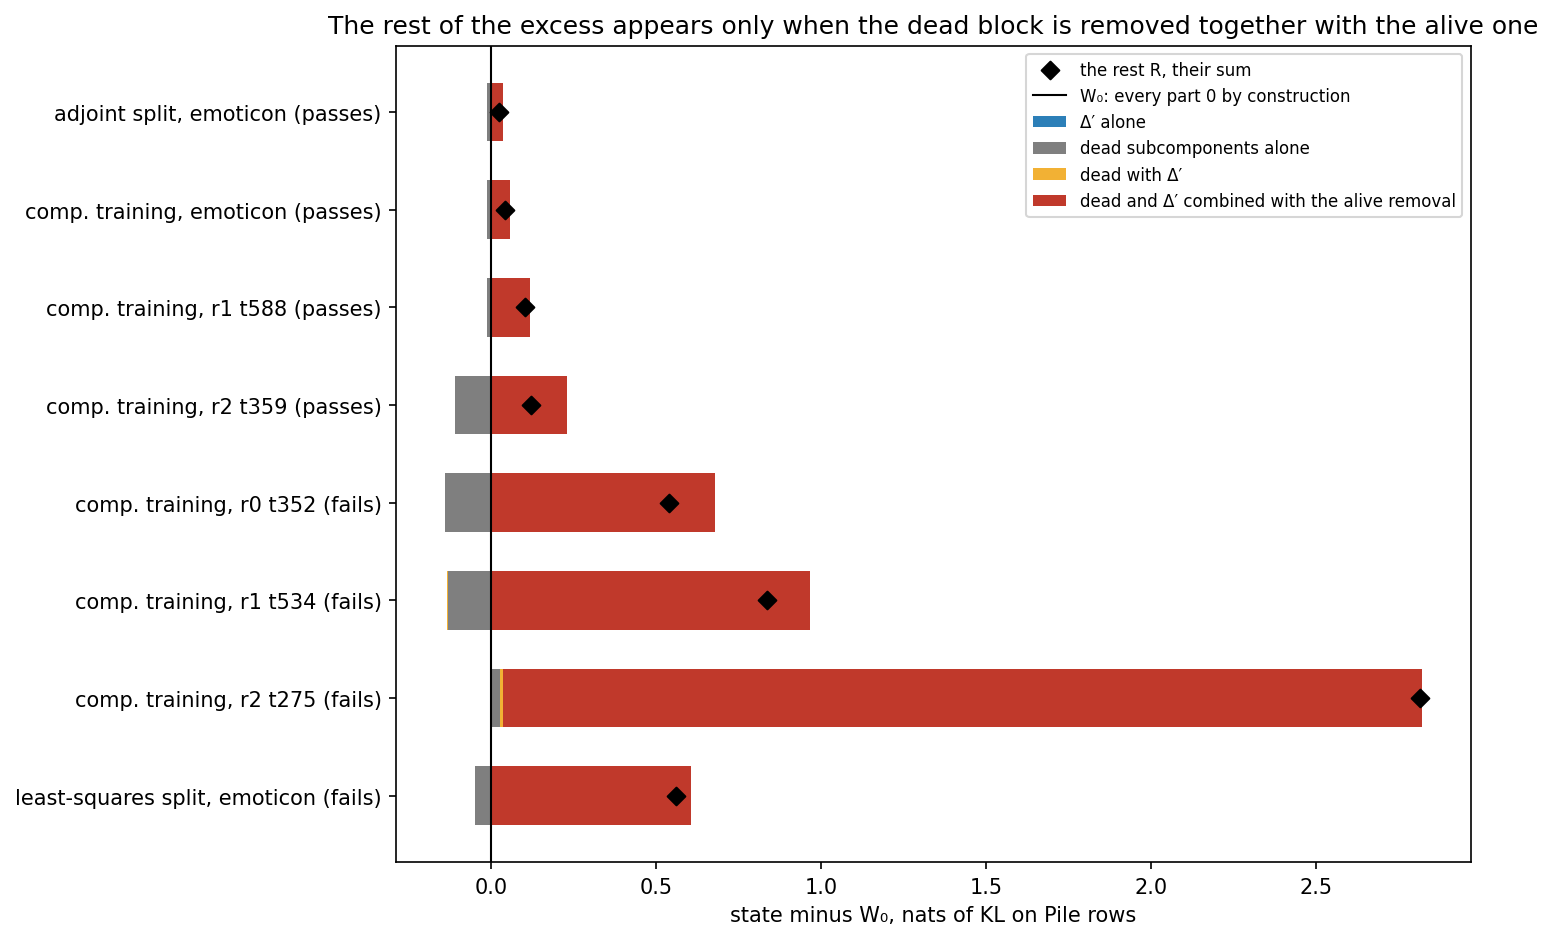

In [6]:
a1 = json.loads((EXP / 'results/complement_amend1.json').read_text())
sp = a1['score']['split']
print(f"gates passed: {all(v['ok'] for v in a1['score']['G2_reproduces_E20'].values())}; {a1['seconds']:.0f} s")
display(Image(EXP / 'figures/rest_split.png'))

**Reading it.** The excess appears only when the dead block and Δ′ are removed together with the alive block. The red
part, that interaction, is at least 0.99 of the rest on every model. Δ′ alone costs under a hundredth of a nat
everywhere and does not change. The dead block alone costs about one nat, and slightly less after the update, so it
sits left of zero. At the original model the alive and dead removals offset each other strongly. Apart they cost 0.49
and 1.07 nats; together, as the adversary's mask, 0.66. At the failing models much of that offset is gone.

In [7]:
rows = ['| model | rest, nats | interaction ÷ rest | change in removed Δ′ | change in removed dead |', '|---|---|---|---|---|']
for k, name in NAMES.items():
    d = sp[k]
    rows.append(f"| {name} | {d['R']:.3f} | {d['J'] / d['R']:.2f} | {d['d_dense_mean']:+.2f} | {d['d_dead_mean']:+.2f} |")
display(Markdown('\n'.join(rows)))

| model | rest, nats | interaction ÷ rest | change in removed Δ′ | change in removed dead |
|---|---|---|---|---|
| adjoint split, emoticon | 0.022 | 1.58 | +0.01 | -0.00 |
| component training, emoticon | 0.043 | 1.31 | +0.02 | -0.02 |
| component training, r1 t588 | 0.104 | 1.13 | -0.08 | -0.04 |
| component training, r2 t359 | 0.121 | 1.88 | +0.02 | -0.10 |
| component training, r0 t352 | 0.538 | 1.26 | -0.20 | -0.10 |
| component training, r1 t534 | 0.835 | 1.16 | -0.10 | -0.11 |
| component training, r2 t275 | 2.817 | 0.99 | +0.10 | -0.19 |
| least-squares split, emoticon | 0.559 | 1.08 | -0.05 | -0.06 |

**Something unexpected happened that I cannot explain.** We predicted the adversary's levels on Δ′ and the dead
block would not move. On three of the four failing models they moved by more than 0.1. It removes less of the dead
block after the update, yet its mask does more damage. A second surprise: at the original model, keeping the alive
block whole is a choice the adversary could make. With its own dead and Δ′ levels that choice costs 1.08 nats, more
than the 0.66 its search found.

Candidate readings, none verified. The excess may partly measure where a short search lands. A stronger adversary at the
original model separates that: if it reaches about 1.1 nats, the reference is understated. Or the same mask costs more
after the update. The original model's saved levels applied at the updated model separate that. The report gives both
tests and a third reading.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| G2 | repeats E20; new cache right | three totals within 0.001 relative; hooks within 1e-4 | 0.0; ≤ 1.1e-7 | pass |
| P4 | only jointly with the alive removal | interaction ≥ half the rest on 3 of 4 | 1.26, 1.16, 0.99, 1.08 of the rest | **pass** |
| P5 | the levels do not move | both within 0.1 on 3 of 4 | 1 of 4 | **fail** (predicted pass) |

Not run: the original model's levels for every block at the updated models; a stronger adversary. Results
`results/complement_amend1.json`, sha256 `75c9f8b9df780…`; sources `results/large/sources/`; job 28251, 531 s, $0.

## Amendment 2 (2026-10-21): the original model's mask at the updated models, and a stronger adversary

**Something unexpected happened that I cannot explain.** We expected a longer search to raise the original model's
adversarial KL from 0.66 to about 1.1 nats. After 100 sign steps it read 14 nats, and the failing model read 33. Neither
curve has levelled off. The project's adversarial check stops after 20 steps. So every adversarial pass or fail so far
compared two short searches, each far below what the same adversary reaches when run longer. Which verdicts would
change has not been measured; the report lists the claims that rest on the check, not re-judged.

This amendment ran two things. First, the original model's own saved mask, applied unchanged at each updated model.
If the failing models' excess were the same mask doing more harm, it would show here. Second, the same adversary run
longer at the original model and at one failing model. It started from three random seeds and from a mask that keeps
every alive subcomponent whole. Every saved mask and 20-step value reproduced Amendment 1 exactly.

controls passed; 101 s and 628 s


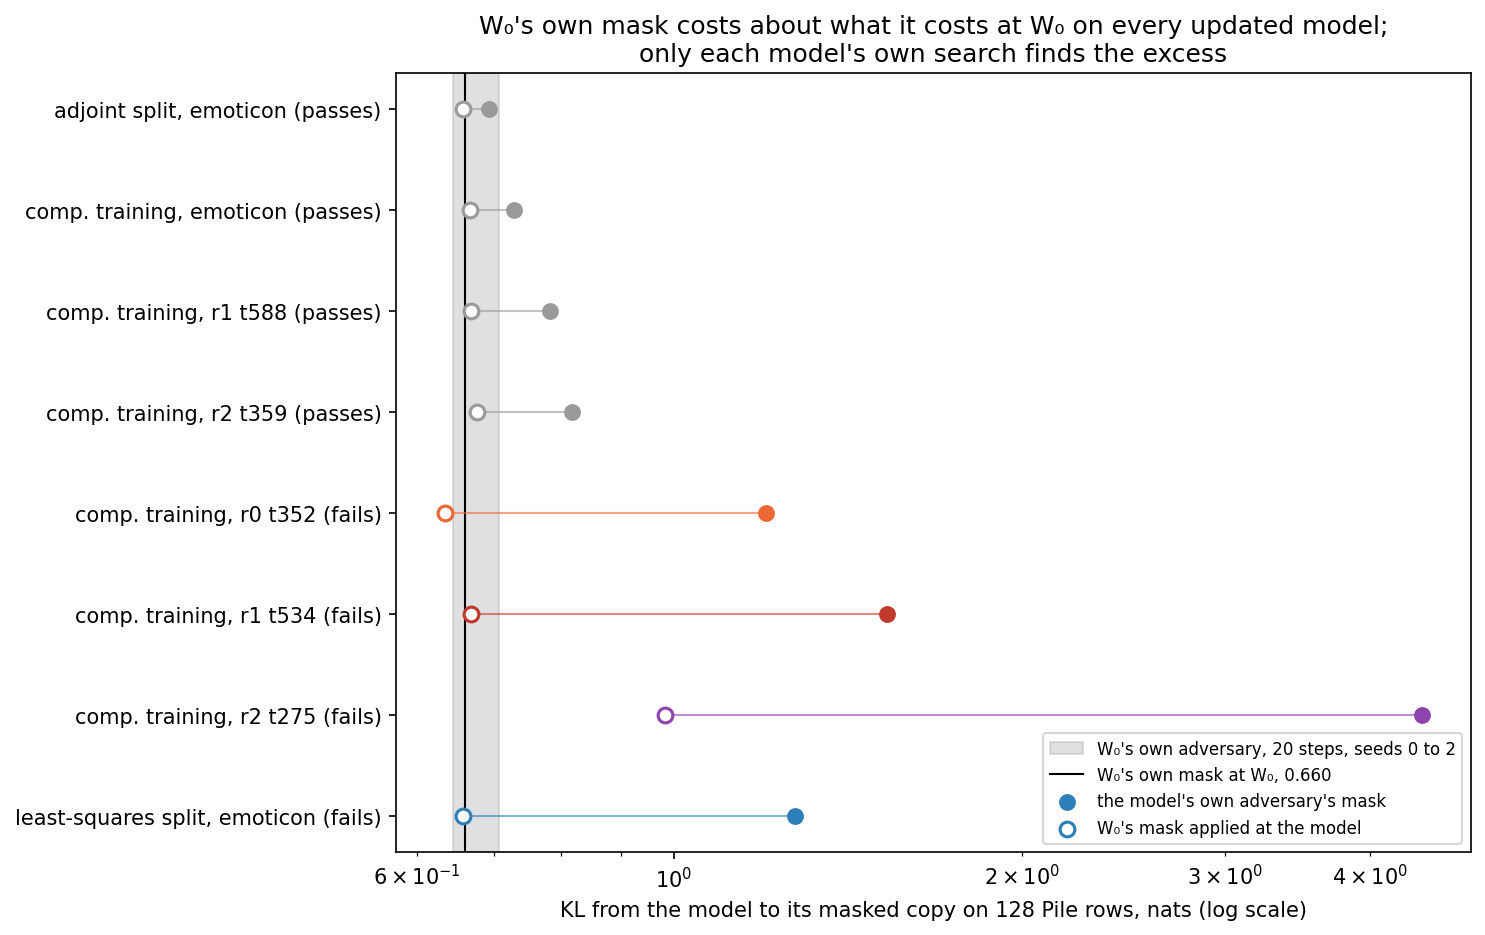

In [8]:
fx = json.loads((EXP / 'results/complement_amend2_fixed.json').read_text())
sg = json.loads((EXP / 'results/complement_amend2_strong.json').read_text())
assert fx['C1']['ok'] and all(r['G3']['ok'] for r in fx['states'].values()) and all(v['ok'] for v in sg['C2'].values())
print(f"controls passed; {fx['seconds']:.0f} s and {sg['seconds']:.0f} s")
display(Image(EXP / 'figures/amend2_w0_mask.png'))

**Reading it.** No, the original model's mask does not cost more at the updated models. Each open circle sits on or
near the black line at 0.660, where the filled circles of the failing models sit far to the right. On three failing
models it carries a twentieth of the excess or less. On r2 t275 it costs a third of a nat more, still under a tenth of
that model's excess. So each failing model's own adversary found a different mask.

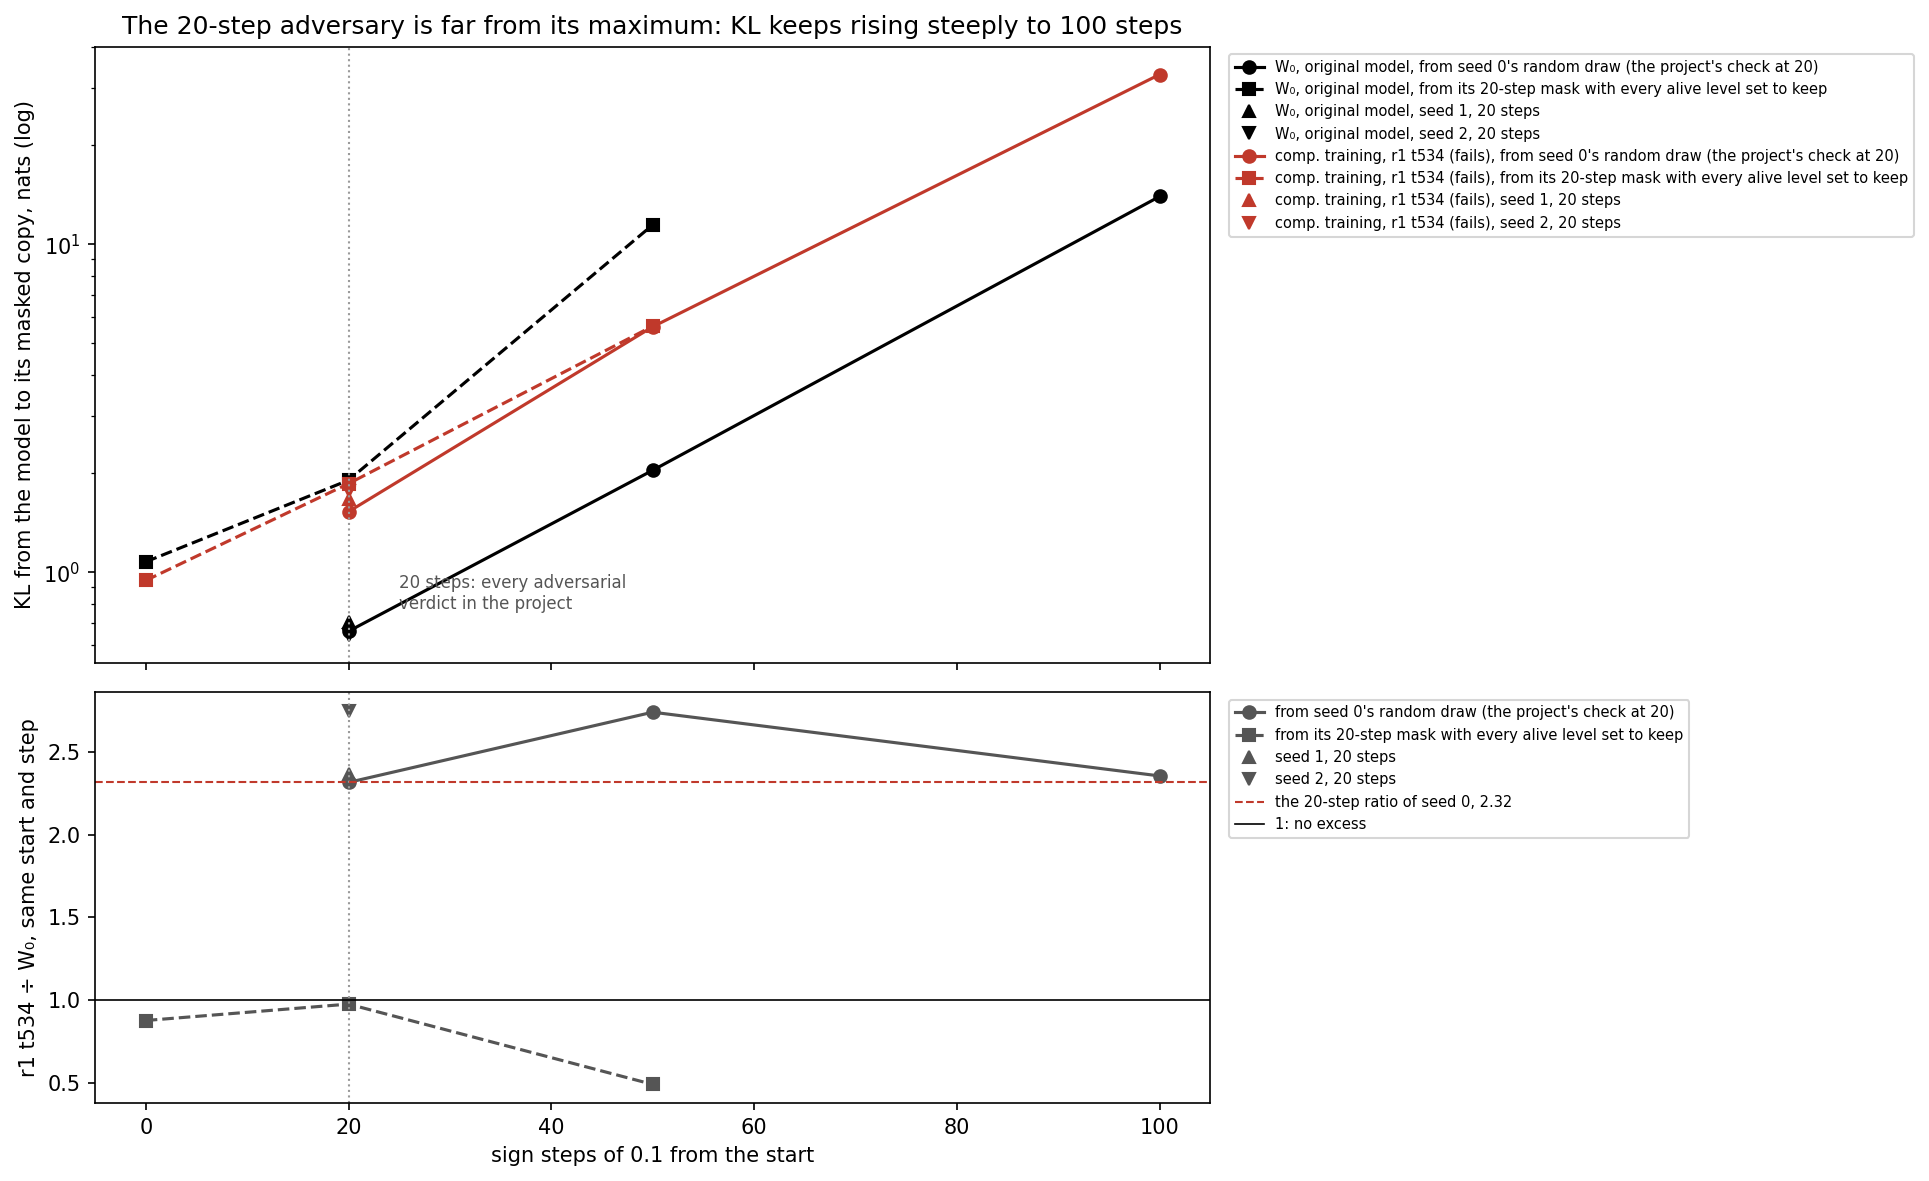

| model | 20 steps | 50 steps | 100 steps |
|---|---|---|---|
| original model | 0.66 | 2.04 | 13.98 |
| component training, r1 t534 | 1.53 | 5.60 | 32.90 |

In [9]:
display(Image(EXP / 'figures/amend2_steps.png'))
rows = ['| model | 20 steps | 50 steps | 100 steps |', '|---|---|---|---|']
for k, name in (('W0', 'original model'), ('ct r1_t534_v369', 'component training, r1 t534')):
    s0 = sg['kl'][k]['seed0']
    rows.append(f"| {name} | {s0['20']:.2f} | {s0['50']:.2f} | {s0['100']:.2f} |")
display(Markdown('\n'.join(rows)))

**Reading it.** The 20-step adversary is far from its maximum. Every run in the top panel climbs steeply on a log
scale. The three seeds agree at 20 steps, so the short search is repeatable; it is just short. The bottom panel
divides the failing model by the original at the same start and step. From random starts it stays over twice the
original's at every step. From the alive-whole start it falls below the original's, so there is no excess. One pair of
models and an unconverged search cannot show that the ratio is stable across budgets.

**What next is the user's choice**, listed without a recommendation. Keep the 20-step adversary and call it a
fixed-budget probe in every verdict. Or measure whether the pass and fail order holds across budgets and starts on a
few states, in one or two free debug jobs. Or converge the adversary with a decaying step size and reread the
verdicts, which may also need a new pass line.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| C1, G3, C2 | saved masks and the longer search reproduce Amendment 1 | 1e-6 nats; 1e-4 nats; 1e-3 relative | exact; exact; within 7e-8 nats | pass |
| P6 | the same mask costs more after the update | share ≥ 0.5 on 3 of 4 failing | −0.05, +0.01, +0.09, −0.00 | **fail**, as predicted |
| P7 | the original model's floor is understated | largest KL ≥ 1.0 nats | 13.98 | **pass**, far beyond 1.1 |
| P8 | the excess is partly the search | longer-search excess ≤ 0.6 of 0.868 | 18.9 | **fail**, predicted pass |

Not run: the longer search on other models or past 100 steps; a step-size schedule; the harness's own check at more
steps. Results: `results/complement_amend2_fixed.json`, sha256 `04283877…`, and `complement_amend2_strong.json`,
sha256 `3896b799…`. Cluster jobs 28306 and 28307, $0.